# Homework B — Time-Series Analysis and Forecasting
**Abiell Yuman Atsal · 23625313 · Group 3 · AE5004**

Monthly NOAA CO₂ analysis following the supplied feature-based forecasting tutorial. Run from top to bottom. The exact data vintage is loaded from GitHub, with manual CSV upload as a fallback. Outputs are saved in `outputs_B/`.

Training targets end in December 2014. Testing covers January 2015–September 2026. Forecasts are one month ahead with observed monthly updates and fixed fitted models.

## 1. Software and data

In [1]:
# Install the versions used in the report only when needed.
import sys, subprocess
from importlib.metadata import version, PackageNotFoundError
requirements = {'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1',
                'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}
missing = []
for package, wanted in requirements.items():
    try:
        if version(package) != wanted:
            missing.append(f'{package}=={wanted}')
    except PackageNotFoundError:
        missing.append(f'{package}=={wanted}')
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print({package: version(package) for package in requirements})


{'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}


In [2]:
from pathlib import Path
import json, hashlib
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE = Path.cwd() / 'outputs_B ' .strip()
BASE.mkdir(exist_ok=True)
FIG = BASE / 'figures'
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, bbox_inches='tight')
    plt.show()
    plt.close()
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import statsmodels.api as sm


In [3]:
filename = 'co2_mm_mlo.csv'
expected_sha256 = 'd895fb5b4a59fb5e4cd98e69b7667fe5bef595c6581f630852b12cb41c07f675'
candidates = [Path('data') / filename, Path(filename)]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    # Immutable repository revision: uses exactly the supplied data vintage.
    url = 'https://raw.githubusercontent.com/abiellyuman/Assignment-Data-Analytics/be8d6e3f2a0f0fa1e452a9bf65cf58682a38f899/' + filename
    try:
        with urlopen(url, timeout=30) as response:
            content = response.read()
    except Exception:
        # For a private repository or unavailable connection, upload your CSV.
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError('Place ' + filename + ' beside this notebook or in data/.') from exc
        print('Select the supplied file: ' + filename)
        uploaded = files.upload()
        if filename not in uploaded:
            raise ValueError('Expected ' + filename)
        content = uploaded[filename]
    DATA_PATH = Path(filename)
    DATA_PATH.write_bytes(content)
actual = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if actual != expected_sha256:
    raise ValueError('The CSV differs from the version used in the report. Use the supplied original file.')
print('Dataset:', DATA_PATH, '\nSHA256:', actual)


Dataset: data/co2_mm_mlo.csv 
SHA256: d895fb5b4a59fb5e4cd98e69b7667fe5bef595c6581f630852b12cb41c07f675


## 2. Explore the trend and annual cycle
The target is the monthly average concentration in ppm. Negative quality metadata do not represent negative concentrations. The full-sample trend is descriptive and never used for forecasting.

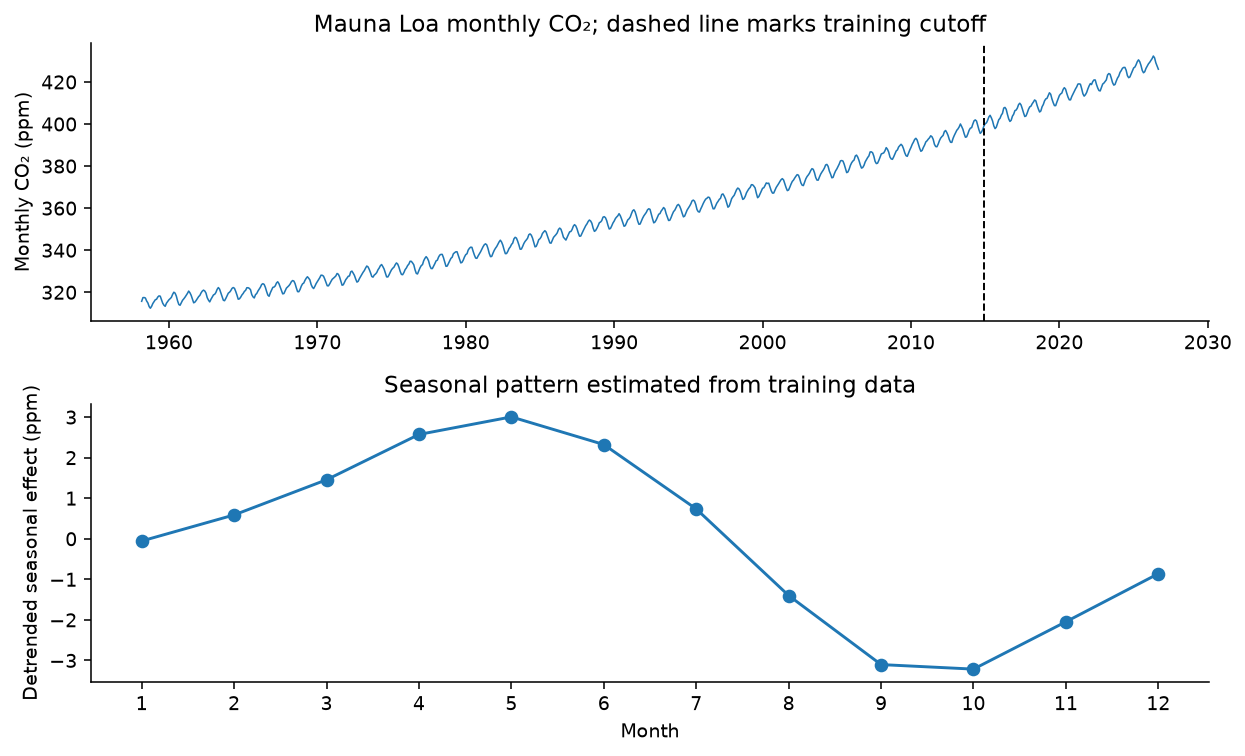

,Value
Original training months,682.000000
Test months,141.000000
Training trend (ppm/year),1.502877
Full-period descriptive trend (ppm/year),1.671015
Seasonal peak-to-trough (ppm),6.218480
Peak month,5.000000
Trough month,10.000000


In [4]:
# NOAA monthly target; flags in quality columns are not missing target values.
c=pd.read_csv(DATA_PATH,comment='#'); c.index=pd.to_datetime(dict(year=c.year,month=c.month,day=1)); c=c.sort_index()
assert not c.index.duplicated().any()
yc=c.average.astype(float).asfreq('MS'); invalid=(yc<=0)|yc.isna(); assert not invalid.any(), 'Missing target requires causal handling'
t=np.arange(len(yc)); cutoff=pd.Timestamp('2014-12-01'); train=yc.index<=cutoff; test=~train
# Descriptive annual linear trend with calendar-month effects.
D=pd.get_dummies(yc.index.month,drop_first=True,dtype=float).to_numpy()
design=np.column_stack([np.ones(len(t)),t/12,D]); ols=sm.OLS(yc.to_numpy()[train],design[train]).fit(); full=sm.OLS(yc.to_numpy(),design).fit()
resid=yc.to_numpy()[train]- (ols.params[0]+ols.params[1]*t[train]/12)
season=pd.Series(resid,index=yc.index[train]).groupby(lambda d:d.month).mean(); season-=season.mean()
fig,ax=plt.subplots(2,1,figsize=(9,5.5)); ax[0].plot(yc.index,yc,lw=.8); ax[0].axvline(cutoff,color='black',ls='--',lw=1); ax[0].set(ylabel='Monthly CO₂ (ppm)',title='Mauna Loa monthly CO₂; dashed line marks training cutoff'); ax[1].plot(range(1,13),season.values,'o-'); ax[1].set(xticks=range(1,13),xlabel='Month',ylabel='Detrended seasonal effect (ppm)',title='Seasonal pattern estimated from training data'); save('b_exploration.png')

display(pd.Series({'Original training months':int(train.sum()), 'Test months':int(test.sum()), 'Training trend (ppm/year)':ols.params[1], 'Full-period descriptive trend (ppm/year)':full.params[1], 'Seasonal peak-to-trough (ppm)':season.max()-season.min(), 'Peak month':int(season.idxmax()), 'Trough month':int(season.idxmin())}).to_frame('Value'))


## 3. Build eight causal monthly features
Rows are indexed by **target month T**. Predictors are lags 1, 2, 3 and 12; mean and OLS slope of the previous 12 months; and sine/cosine of the target calendar month. Rolling windows end at T−1. This is equivalent to the tutorial's origin-indexed one-step formulation, adapted from a 24-hour to a 12-month cycle.

In [5]:
# Tutorial's horizon-one features, indexed here by target month T.
def features(s):
 f=pd.DataFrame(index=s.index)
 f['lag1']=s.shift(1); f['lag2']=s.shift(2); f['lag3']=s.shift(3); f['lag12']=s.shift(12)
 f['mean12']=s.shift(1).rolling(12).mean()
 f['slope12']=s.shift(1).rolling(12).apply(lambda a:np.polyfit(np.arange(len(a)),a,1)[0],raw=True)
 f['sin_month']=np.sin(2*np.pi*s.index.month/12); f['cos_month']=np.cos(2*np.pi*s.index.month/12)
 return f
f=features(yc); valid=f.notna().all(axis=1); tr=train&valid; te=test&valid
assert tr.sum()==670 and te.sum()==141

print('Usable training rows:', int(tr.sum()), '; test rows:', int(te.sum()))
print('Last training target:', yc.index[tr].max(), '; first test target:', yc.index[te].min())
display(f.loc[tr].head())


Usable training rows: 670 ; test rows: 141
Last training target: 2014-12-01 00:00:00 ; first test target: 2015-01-01 00:00:00


,lag1,lag2,lag3,lag12,mean12,slope12,sin_month,cos_month
1959-03-01,316.49,315.58,314.67,315.71,315.370000,-0.209441,1.000000e+00,6.123234e-17
1959-04-01,316.65,316.49,315.58,317.45,315.448333,-0.144755,8.660254e-01,-5.000000e-01
1959-05-01,317.72,316.65,316.49,317.51,315.470833,0.033601,5.000000e-01,-8.660254e-01
1959-06-01,318.29,317.72,316.65,317.27,315.535833,0.234720,1.224647e-16,-1.000000e+00
1959-07-01,318.15,318.29,317.72,315.87,315.609167,0.414091,-5.000000e-01,-8.660254e-01


## 4. Fit models and evaluate
Naive predicts the previous month. Linear regression and random forest use the same features. Forest settings match the tutorial: 300 trees, minimum leaf size 3, seed 0. There is no random split or test-period model refitting. Later test months may use earlier **observed** test months because these are sequential one-step forecasts.

In [6]:
lr=LinearRegression().fit(f.loc[tr],yc.loc[tr])
rf=RandomForestRegressor(n_estimators=300,min_samples_leaf=3,random_state=0,n_jobs=2).fit(f.loc[tr],yc.loc[tr])
preds={'Naive baseline':f.loc[te,'lag1'].to_numpy(),'Linear regression':lr.predict(f.loc[te]),'Random forest':rf.predict(f.loc[te])}
scores={k:{'MAE':float(mean_absolute_error(yc.loc[te],a)),'RMSE':float(np.sqrt(mean_squared_error(yc.loc[te],a)))} for k,a in preds.items()}
assert preds['Random forest'].max()<=yc.loc[tr].max()+1e-8
# A target month's predictors must remain unchanged if that target and all later values change.
for target in ['2015-01-01','2020-06-01','2026-09-01']:
 altered=yc.copy(); altered.loc[target:]=9999
 np.testing.assert_allclose(features(altered).loc[target],f.loc[target])

score_table = pd.DataFrame(scores).T
display(score_table.rename(columns={'MAE':'MAE (ppm)', 'RMSE':'RMSE (ppm)'}))
display(pd.Series(lr.coef_, index=f.columns, name='Linear regression coefficient').to_frame())
score_table.to_csv(BASE / 'forecast_metrics.csv')


,MAE (ppm),RMSE (ppm)
Naive baseline,1.202624,1.351323
Linear regression,0.373877,0.481273
Random forest,14.432574,16.867937


,Linear regression coefficient
lag1,0.434151
lag2,-0.659394
lag3,-0.171501
lag12,0.422454
mean12,0.980998
slope12,5.283717
sin_month,2.213860
cos_month,-0.566829


## 5. Forecast plots and saved predictions

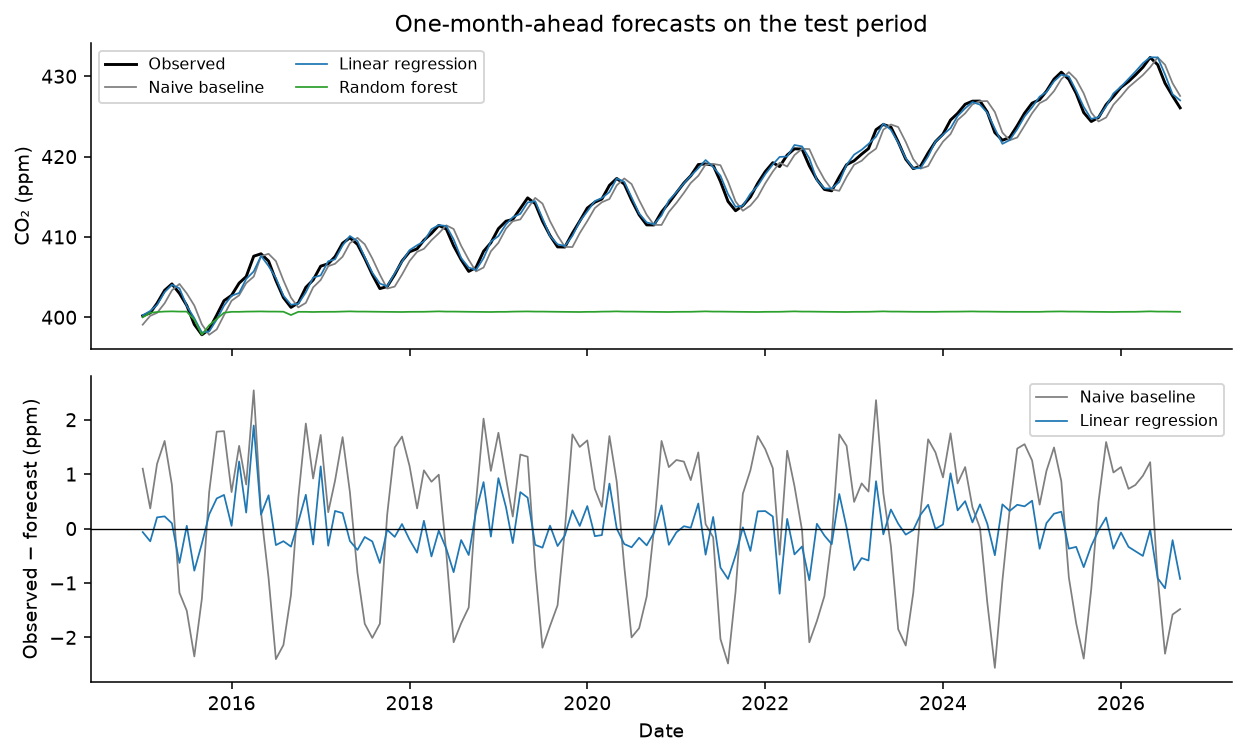

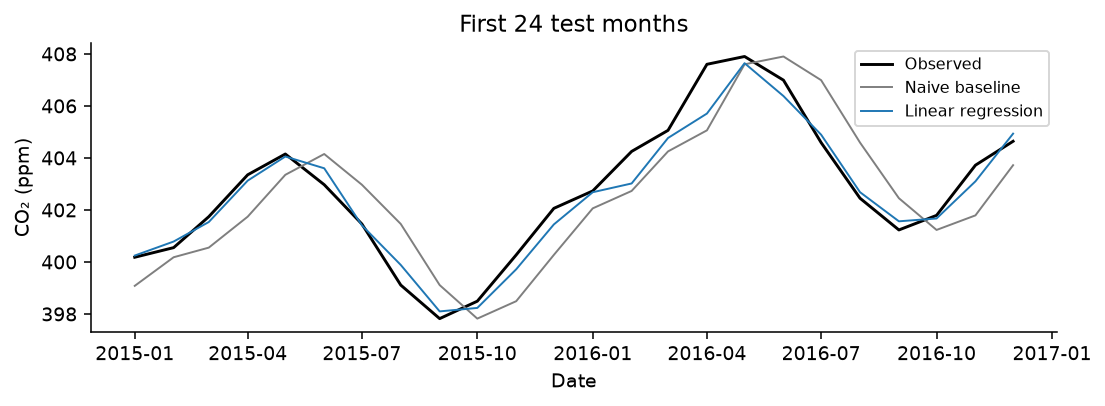

In [7]:
fig,ax=plt.subplots(2,1,figsize=(9,5.5),sharex=True)
ax[0].plot(yc.loc[te],color='black',lw=1.5,label='Observed')
colors={'Naive baseline':'tab:gray','Linear regression':'tab:blue','Random forest':'tab:green'}
for key,a in preds.items(): ax[0].plot(yc.index[te],a,color=colors[key],lw=.9,label=key)
ax[0].set(ylabel='CO₂ (ppm)',title='One-month-ahead forecasts on the test period');ax[0].legend(fontsize=8,ncol=2)
for key in ['Naive baseline','Linear regression']:
 ax[1].plot(yc.index[te],yc.loc[te].to_numpy()-preds[key],color=colors[key],label=key,lw=.9)
ax[1].axhline(0,color='black',lw=.7);ax[1].set(xlabel='Date',ylabel='Observed − forecast (ppm)');ax[1].legend(fontsize=8)
save('b_forecasts.png')
fig,ax=plt.subplots(figsize=(8,3)); ax.plot(yc.loc[te].iloc[:24],color='black',label='Observed',lw=1.5)
for key in ['Naive baseline','Linear regression']:
 ax.plot(yc.index[te][:24],preds[key][:24],color=colors[key],label=key,lw=1)
ax.set(ylabel='CO₂ (ppm)',xlabel='Date',title='First 24 test months'); ax.legend(fontsize=8);save('b_detail.png')
pd.DataFrame({'observed':yc.loc[te],**preds}).to_csv(BASE/'forecast_results.csv')


In [8]:
summary = {'n':len(yc), 'n_train':int(train.sum()), 'n_model_train':int(tr.sum()),
           'n_test':int(te.sum()), 'slope_train':float(ols.params[1]),
           'slope_full':float(full.params[1]), 'amplitude':float(season.max()-season.min()),
           'scores':scores}
(BASE / 'results_B.json').write_text(json.dumps(summary, indent=2))
print('Results saved to', BASE)


Results saved to /workspace/revised_submission/notebook_validation/B/outputs_B


## Conclusion
Feature-based linear regression performs best among these three models (MAE 0.374 ppm; RMSE 0.481 ppm). It follows the seasonal cycle more closely than the naive baseline. Random forest underpredicts the rising test series because its predictions stay within the range of training targets. These results are for sequential one-month-ahead forecasting, not an uninterrupted forecast made in December 2014.

## Sources and limitations
NOAA Global Monitoring Laboratory, gml.noaa.gov/ccgg/trends/; supplied file created 9 October 2026. Course tutorial: `(For_students)_feature_based_forecasting_colab.ipynb`. The evaluation uses a single historical data vintage and assumes the previous month's concentration is available before the next forecast. No prediction intervals or real-time data-vintage backtest are claimed.